# Brachistochrone trajectories for the binomial code: a terminating graded expansion

Companion to `gkp_brachistochrone_graded_trajectory.ipynb`, and the positive control that notebook
asked for in its §12.3. Same machinery, same function names, same three truncation schemes — only
the target changes, from a GKP lattice state to a binomial codeword

$$|W_{\uparrow/\downarrow}\rangle=\frac1{2^{N/2}}\sum_{\substack{p=0\\ p\ \mathrm{even/odd}}}^{N+1}
\sqrt{\binom{N+1}{p}}\;\bigl|p(S+1)\bigr\rangle ,$$

whose Fock support is **finite by construction** (Michael *et al.*, PRX **6**, 031006 (2016)).
That single change turns every asymptotic statement in the GKP notebook into an exact one.

The generator is unchanged, in the convention of `brachistochrone.py`
($\phi=\arg\langle\psi_i|\psi_f\rangle$, $H=\omega[\sin\phi\,\sigma^x_{\rm eff}+\cos\phi\,\sigma^y_{\rm eff}]$):

$$H_{\rm opt} \;=\; i\omega\,e^{-i\phi}R\,\mathcal N
\sum_{n\ge1}\sum_{k\ge0}\frac{(-1)^k}{n!\,k!}\,S_n\,
\hat a^{\dagger\,n+k}\hat a^{k}\;+\;{\rm h.c.},
\qquad S_n=\sqrt{n!}\,\langle n|W\rangle ,$$

and so are the three ways to truncate it:

| scheme | index set | meaning | behaviour on a binomial target |
|---|---|---|---|
| `bare` | $k=0$, $n\le D$ | pure $n$-photon drive | finite limit, but the **wrong operator** |
| `photon` | $n\le D$, $k$ complete | exact vacuum projector, $n$ truncated | **exact at finite $D$** |
| `degree` | $n+2k\le D$ | the grading in the `.tex` | exact only at $D\sim2\dim_{\rm F}$ |

### Headline results derived and verified below

1. **A $\mathbb Z_{2(S+1)}$ selection rule**, strictly stronger than the GKP parity rule: $S_n=0$
   unless $n\equiv0 \pmod{2(S+1)}$ for $|W_\uparrow\rangle$. At the working point $(S,N)=(1,3)$ the
   *entire* time-optimal generator is two terms, $n\in\{4,8\}$.
2. **The expansion terminates exactly.** $H_{\rm photon}(D)=H_{\rm exact}$ to machine zero for all
   $D\ge n_{\max}=2(S+1)\lfloor(N+1)/2\rfloor$, at *every* Fock cutoff. This is the statement the GKP
   notebook could only approach asymptotically.
3. **Closed-form staircase.** The peak fidelity is a truncated binomial partial sum,
   $$F_\star(D)=2^{-N}\!\!\sum_{\substack{p\ \mathrm{even}\\ p(S+1)\le D}}\!\!\binom{N+1}{p},$$
   a step function with $\lfloor(N+1)/2\rfloor+1$ risers that reaches exactly $1$, not $1-\epsilon$.
4. **$D_\star$ is the stellar rank.** $D_\star=n_{\max}=2\,\bar n$ (odd $N$), where $\bar n=(S+1)(N+1)/2$.
   Binomial states have finite stellar rank, so the required non-linear order is finite; GKP states
   have infinite stellar rank, so it is not. Same formula, both answers.
5. **The `degree` scheme's failure is now diagnosable exactly.** It becomes exact at
   $D=2\dim_{\rm F}-n_{\min}-2$ — an order set by the *numerical cutoff*, not the physics. Verified at
   four cutoffs. The projector, not the $n$-tail, is what it gets wrong.
6. **Matched-$\bar n$ comparison.** At $\bar n=4$ the binomial code needs $D_\star=8$ with zero
   residual infidelity; GKP at $\Delta=0.33$ needs $D=22$ for $F_\star=0.99$ and never terminates.

## 1. Setup

Pure NumPy/SciPy so this runs in the sandbox kernel (no JAX). The project imports are guarded and
used only for cross-checks; when `jaxquantum` is present, `utils.compute_wigner` and
`plotting.plot_wigner` are preferred over the local fallbacks in §10.

`states.py` has no binomial constructor, so §2 validates the target against the Knill-Laflamme
loss conditions instead of against the module.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from math import pi, sqrt, comb
from scipy.special import gammaln, eval_laguerre

np.set_printoptions(precision=5, suppress=True, linewidth=110)
trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy >= 2.0 renamed trapz

try:
    from gkp_optimal_control.brachistochrone import quantum_brachistochrone_hamiltonian
    from gkp_optimal_control.utils import compute_wigner, to_qarray
    HAVE_PROJECT = True
except Exception as exc:          # ModuleNotFoundError, or JAX missing
    HAVE_PROJECT = False
    _PROJECT_EXC = exc

print("project modules:", "found" if HAVE_PROJECT else f"not found ({type(_PROJECT_EXC).__name__})")

# Publication-ish defaults. plotting.set_plot_style() additionally sets text.usetex=True,
# which needs a LaTeX install, so it is not called here.
plt.rcParams.update({"font.family": "serif", "font.size": 11, "axes.labelsize": 11,
                     "axes.titlesize": 12, "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "legend.frameon": False})

# ---- working point -------------------------------------------------------
BRANCH    = "up"         # logical |W_up> (the one with vacuum support)
S_SPACE   = 1            # spacing parameter: level spacing S+1, corrects S photon losses
N_TRUNC   = 3            # truncation parameter: p runs 0..N+1
DIM       = 40           # Fock truncation (only needs to exceed n_max; see sec 2)
OMEGA     = 1.0          # energy scale: ||H_exact||_2 = OMEGA

N_MAX     = 2 * (S_SPACE + 1) * ((N_TRUNC + 1) // 2)   # highest occupied Fock level
N_BANDS   = (N_TRUNC + 1) // 2                          # number of surviving n-bands

print(f"(S, N) = ({S_SPACE}, {N_TRUNC}),  branch = |W_{BRANCH}>,  dim_F = {DIM}")
print(f"n_max = {N_MAX}   surviving bands = {N_BANDS}   nbar = {(S_SPACE + 1) * (N_TRUNC + 1) / 2}")

project modules: found
(S, N) = (1, 3),  branch = |W_up>,  dim_F = 40
n_max = 8   surviving bands = 2   nbar = 4.0


## 2. Binomial moments and the target state

The target enters through the same moment family as in the GKP notebook, but there is no lattice sum
to converge — the moments are a closed form read straight off the definition,

$$\langle n|W_{\uparrow/\downarrow}\rangle=\frac1{2^{N/2}}\sqrt{\binom{N+1}{p}}\;
\delta_{n,\,p(S+1)},\qquad S_n=\sqrt{n!}\,\langle n|W\rangle ,\qquad \mathcal N=1 .$$

Everything downstream follows from these, and all of the derived scalars are exact rationals or
inverse cosines of them:

$$s=\langle0|W_\uparrow\rangle=2^{-N/2},\qquad \phi=0,\qquad
R=\bigl(1-2^{-N}\bigr)^{-1/2},\qquad \theta_B=\arccos 2^{-N/2},\qquad
\bar n=\frac{(S+1)(N+1)}2 .$$

Note what is *absent* relative to the GKP case. There is no lattice cutoff, no cancellation between
large terms, and no conditioning warning: `DIM` has only to exceed $n_{\max}$, after which every
quantity below is exactly `DIM`-independent. That is the whole reason this target is a usable control.

In [2]:
def binomial_amplitudes(nmax, branch, S, N):
    """<n|W_branch> for n = 0..nmax, from the closed form (Michael et al. 2016)."""
    c = np.zeros(nmax + 1, float)
    parity = 0 if branch == "up" else 1
    for p in range(0, N + 2):
        if p % 2 != parity:
            continue
        level = p * (S + 1)
        if level <= nmax:
            c[level] = sqrt(comb(N + 1, p)) / 2 ** (N / 2)
    return c


def binomial_moments(nmax, branch, S, N):
    """S_n = sqrt(n!) <n|W>.  The binomial analogue of `lattice_moments` (notebook 2)."""
    c = binomial_amplitudes(nmax, branch, S, N)
    return c * np.exp(0.5 * gammaln(np.arange(nmax + 1) + 1.0))


def target_from_moments(dim, S):
    """(normalized |W> in the Fock basis, N).  Identical API to notebook 2."""
    v = S[:dim] / np.exp(0.5 * gammaln(np.arange(dim) + 1.0))
    nrm = np.linalg.norm(v)
    return v / nrm, 1.0 / nrm


def reference_scalars(psi, omega=OMEGA):
    s = psi[0]
    a = min(abs(s), 1.0)
    return dict(s=s, phi=float(np.angle(s)), R=1.0 / sqrt(1.0 - a ** 2),
                theta_B=float(np.arccos(a)), T_star=float(np.arccos(a)) / omega)


S_MOM = binomial_moments(DIM - 1, BRANCH, S_SPACE, N_TRUNC)
PSI_F, NRM = target_from_moments(DIM, S_MOM)
REF = reference_scalars(PSI_F)
T_STAR = REF["T_star"]

nbar = float(np.sum(np.arange(DIM) * np.abs(PSI_F) ** 2))
support = [int(n) for n in np.flatnonzero(np.abs(PSI_F) > 1e-14)]
print(f"support = {support}   (n_max = {N_MAX})")
print(f"|s| = {abs(REF['s']):.12f}   2^(-N/2) = {2.0 ** (-N_TRUNC / 2):.12f}")
print(f"phi = {REF['phi']:+.3e}   R = {REF['R']:.12f}   Nrm = {NRM:.12f}  (exactly 1)")
print(f"theta_B = {REF['theta_B']:.12f}   arccos 2^(-N/2) = {np.arccos(2.0 ** (-N_TRUNC / 2)):.12f}")
print(f"T* = {T_STAR:.12f}   nbar = {nbar:.12f}   (S+1)(N+1)/2 = {(S_SPACE + 1) * (N_TRUNC + 1) / 2}")

support = [0, 4, 8]   (n_max = 8)
|s| = 0.353553390593   2^(-N/2) = 0.353553390593
phi = +0.000e+00   R = 1.069044967650   Nrm = 1.000000000000  (exactly 1)
theta_B = 1.209429202888   arccos 2^(-N/2) = 1.209429202888
T* = 1.209429202888   nbar = 4.000000000000   (S+1)(N+1)/2 = 4.0


In [3]:
# The knob that mattered for GKP -- Fock cutoff -- does nothing here beyond n_max.
print(" dim   |s|              nbar           theta_B         weight above n_max")
for dim_try in (12, 20, 40, 80, 150):
    S_d = binomial_moments(dim_try - 1, BRANCH, S_SPACE, N_TRUNC)
    psi_d, _ = target_from_moments(dim_try, S_d)
    ref_d = reference_scalars(psi_d)
    print(f"{dim_try:4d}   {abs(ref_d['s']):.12f}   {np.sum(np.arange(dim_try) * abs(psi_d) ** 2):.10f}"
          f"   {ref_d['theta_B']:.10f}   {np.sum(np.abs(psi_d[N_MAX + 1:]) ** 2):.1e}")
print("\n=> exactly dim-independent once dim > n_max. Contrast notebook 2 sec 2, where |s| and")
print("   nbar were still moving at dim_F = 80 and the lattice cutoff had to be swept too.")

 dim   |s|              nbar           theta_B         weight above n_max
  12   0.353553390593   4.0000000000   1.2094292029   0.0e+00
  20   0.353553390593   4.0000000000   1.2094292029   0.0e+00
  40   0.353553390593   4.0000000000   1.2094292029   0.0e+00
  80   0.353553390593   4.0000000000   1.2094292029   0.0e+00
 150   0.353553390593   4.0000000000   1.2094292029   0.0e+00

=> exactly dim-independent once dim > n_max. Contrast notebook 2 sec 2, where |s| and
   nbar were still moving at dim_F = 80 and the lattice cutoff had to be swept too.


In [4]:
# Independent validation: the Knill-Laflamme conditions for l-photon loss.
# <W_i| adag^l a^l |W_j> = delta_ij c_l must hold for l <= N if this really is the
# binomial code. Nothing in this check reuses the moment machinery above.
def annihilation(dim):
    return np.diag(np.sqrt(np.arange(1, dim)), 1)


def kl_first_failure(S, N, dim=100, tol=1e-8):
    psi_u, _ = target_from_moments(dim, binomial_moments(dim - 1, "up", S, N))
    psi_d, _ = target_from_moments(dim, binomial_moments(dim - 1, "down", S, N))
    a, rows = annihilation(dim), []
    for l in range(0, N + 3):
        Al = np.linalg.matrix_power(a, l)
        M = Al.conj().T @ Al
        uu, dd = np.real(psi_u.conj() @ M @ psi_u), np.real(psi_d.conj() @ M @ psi_d)
        ud = abs(psi_u.conj() @ M @ psi_d)
        bad = abs(uu - dd) > tol * max(1.0, abs(uu)) or ud > tol
        rows.append((l, uu, abs(uu - dd), ud, bad))
    first = next((l for l, *_, bad in rows if bad), None)
    return rows, first


rows, first = kl_first_failure(S_SPACE, N_TRUNC)
print(f"Knill-Laflamme loss conditions at (S, N) = ({S_SPACE}, {N_TRUNC}):")
print("   l   <adag^l a^l>_up   |diag mismatch|   |off-diagonal|")
for l, uu, dif, ud, bad in rows:
    print(f"  {l:2d}   {uu:15.8f}   {dif:15.2e}   {ud:14.2e}" + ("   <- fails" if bad else ""))
print(f"\nfirst failure at l = {first}, i.e. the conditions hold for l <= N = {N_TRUNC}.")

print("\nsame check across the family (first failing loss order):")
for (S_t, N_t) in [(1, 1), (1, 2), (1, 3), (1, 5), (2, 2), (2, 3), (3, 3), (3, 4)]:
    _, f_t = kl_first_failure(S_t, N_t)
    print(f"  S={S_t} N={N_t}:  holds for l <= {f_t - 1},  N = {N_t}"
          + ("  OK" if f_t - 1 == N_t else "  MISMATCH"))

Knill-Laflamme loss conditions at (S, N) = (1, 3):
   l   <adag^l a^l>_up   |diag mismatch|   |off-diagonal|
   0        1.00000000          0.00e+00         0.00e+00
   1        4.00000000          8.88e-16         0.00e+00
   2       16.00000000          0.00e+00         0.00e+00
   3       60.00000000          2.13e-14         0.00e+00
   4      228.00000000          4.80e+01         0.00e+00   <- fails
   5      840.00000000          4.80e+02         0.00e+00   <- fails

first failure at l = 4, i.e. the conditions hold for l <= N = 3.

same check across the family (first failing loss order):
  S=1 N=1:  holds for l <= 1,  N = 1  OK
  S=1 N=2:  holds for l <= 2,  N = 2  OK
  S=1 N=3:  holds for l <= 3,  N = 3  OK
  S=1 N=5:  holds for l <= 5,  N = 5  OK
  S=2 N=2:  holds for l <= 2,  N = 2  OK
  S=2 N=3:  holds for l <= 3,  N = 3  OK
  S=3 N=3:  holds for l <= 3,  N = 3  OK
  S=3 N=4:  holds for l <= 4,  N = 4  OK


## 3. A $\mathbb Z_{2(S+1)}$ selection rule, stronger than GKP parity

The GKP notebook found that square-lattice codestates are $(-1)^{\hat n}$ eigenstates, so $S_n=0$ for
odd $n$ and half the graded expansion vanishes. The binomial codewords carry a larger symmetry. By
construction $|W_\uparrow\rangle$ is supported on levels $p(S+1)$ with $p$ *even*, so

$$S_n=0\quad\text{unless}\quad n\equiv0 \pmod{2(S+1)},$$

and only $\lfloor(N+1)/2\rfloor$ values of $n$ survive at all. For $|W_\downarrow\rangle$ the same
argument gives $n\equiv(S+1)\pmod{2(S+1)}$ — see §12.

At the working point $(S,N)=(1,3)$ that leaves $n\in\{4,8\}$: the exact time-optimal generator is

$$H_{\rm opt}=\bigl(\lambda_4\,\hat a^{\dagger4}+\lambda_8\,\hat a^{\dagger8}\bigr)|0\rangle\langle0|
\;+\;{\rm h.c.},$$

a **finite** polynomial in $\hat a^\dagger$ times the vacuum projector. The GKP generator is the same
expression with an infinite polynomial. That contrast is the whole content of this notebook, and it
is the rank-theoretic statement from the manuscript seen from the other side: the projector is still
irreducibly non-polynomial, but the wave-mixing order it multiplies is now bounded.

In [5]:
print("surviving bands and their Fock amplitudes:")
nz = [n for n in range(1, DIM) if abs(S_MOM[n]) > 0]
for n in nz:
    print(f"  n = {n:2d}   n mod 2(S+1) = {n % (2 * (S_SPACE + 1))}   "
          f"<n|W> = {PSI_F[n]:.8f}")
print(f"  every other n <= {DIM - 1}:  S_n = 0 exactly "
      f"(max |S_n| off-lattice = {max(abs(S_MOM[n]) for n in range(1, DIM) if n not in nz):.1e})")

print(f"\nboth branches, (S, N) = ({S_SPACE}, {N_TRUNC}):")
for br in ("up", "down"):
    S_b = binomial_moments(DIM - 1, br, S_SPACE, N_TRUNC)
    psi_b, _ = target_from_moments(DIM, S_b)
    sup = [int(n) for n in np.flatnonzero(np.abs(psi_b) > 1e-14)]
    print(f"  |W_{br:5s}>: support {sup},  n mod 2(S+1) in "
          f"{sorted({n % (2 * (S_SPACE + 1)) for n in sup})},  <0|W> = {psi_b[0]:.6f}")

print("\nwhich graded blocks survive, d = 1..14 (d = n + 2k):")
for d in range(1, 15):
    live = [n for n in range(1, d + 1) if (d - n) % 2 == 0 and abs(S_MOM[n]) > 0]
    print(f"  d={d:2d}: " + (f"survives, n in {live}" if live else "vanishes"))

surviving bands and their Fock amplitudes:
  n =  4   n mod 2(S+1) = 0   <n|W> = 0.86602540
  n =  8   n mod 2(S+1) = 0   <n|W> = 0.35355339
  every other n <= 39:  S_n = 0 exactly (max |S_n| off-lattice = 0.0e+00)

both branches, (S, N) = (1, 3):
  |W_up   >: support [0, 4, 8],  n mod 2(S+1) in [0],  <0|W> = 0.353553
  |W_down >: support [2, 6],  n mod 2(S+1) in [2],  <0|W> = 0.000000

which graded blocks survive, d = 1..14 (d = n + 2k):
  d= 1: vanishes
  d= 2: vanishes
  d= 3: vanishes
  d= 4: survives, n in [4]
  d= 5: vanishes
  d= 6: survives, n in [4]
  d= 7: vanishes
  d= 8: survives, n in [4, 8]
  d= 9: vanishes
  d=10: survives, n in [4, 8]
  d=11: vanishes
  d=12: survives, n in [4, 8]
  d=13: vanishes
  d=14: survives, n in [4, 8]


## 4. The $k$-sum still has to be resummed analytically

Nothing about the target changes this step: the $k$-sum is the vacuum projector, and it is infinite
regardless of how short the $n$-sum is. The closed form from the GKP notebook carries over verbatim,

$$\chi(q,K)\;\equiv\;\sum_{k=0}^{\min(K,q)}(-1)^k\binom{q}{k}
=\begin{cases}1,& q=0,\\ 0,& 1\le q\le K,\\ (-1)^K\binom{q-1}{K},& q>K,\end{cases}
\qquad
\Bigl[\textstyle\sum_{k\le K}\frac{(-1)^k}{k!}\hat a^{\dagger n+k}\hat a^{k}\Bigr]_{q+n,\,q}
=\sqrt{\frac{(q+n)!}{q!}}\;\chi(q,K),$$

and so does the reason it is mandatory. Summing the monomials explicitly still asks floating point to
cancel terms of size $\sqrt{q!(q+n)!}/(q-k)!$ down to zero, and the price is set by $\binom{q}{q/2}$,
not by the target. The cell below confirms the collapse happens at the same cutoff as before —
the binomial target buys exactly nothing here.

In [6]:
def chi(q, K):
    """Closed-form k-sum; q may be an array."""
    q = np.atleast_1d(np.asarray(q))
    out = np.zeros(q.shape, float)
    out[q == 0] = 1.0
    hi = q > K
    if np.any(hi):
        qq = q[hi].astype(float)
        out[hi] = (-1.0) ** K * np.exp(gammaln(qq) - gammaln(K + 1.0) - gammaln(qq - K))
    return out


def band(dim, n, K):
    """sum_{k<=K} (-1)^k/k! adag^(n+k) a^k, cancellation-free."""
    M = np.zeros((dim, dim))
    q = np.arange(0, max(dim - n, 0))
    if q.size:
        M[q + n, q] = np.exp(0.5 * (gammaln(q + n + 1.0) - gammaln(q + 1.0))) * chi(q, K)
    return M


def monomial(dim, n, k):
    """adag^(n+k) a^k, for cross-checking `band` where cancellation is still harmless."""
    p, q = n + k, k
    M = np.zeros((dim, dim))
    c = np.arange(q, dim)
    r = c - q + p
    ok = r < dim
    c, r = c[ok], r[ok]
    if c.size:
        M[r, c] = np.exp(0.5 * (gammaln(c + 1.0) + gammaln(r + 1.0)) - gammaln(c - q + 1.0))
    return M


def band_explicit(dim, n, K):
    return sum((-1.0) ** k * np.exp(-gammaln(k + 1.0)) * monomial(dim, n, k)
               for k in range(K + 1))


worst = 0.0
for dim_t in (8, 14, 20):
    for n in range(1, 5):
        for K in range(0, 8):
            A, B = band(dim_t, n, K), band_explicit(dim_t, n, K)
            worst = max(worst, np.abs(A - B).max() / max(1.0, np.abs(B).max()))
print(f"band vs explicit monomial sum, dim <= 20: max relative deviation = {worst:.2e}")

band vs explicit monomial sum, dim <= 20: max relative deviation = 1.88e-14


In [7]:
# The same quantity, two ways, as a function of Fock cutoff. Exact answer: 1.0
print(" dim   ||H||_2 analytic   ||H||_2 explicit-k   |explicit - 1|   sigma_3/sigma_1")
for dim_t in (20, 30, 40, 50, 60, 80):
    S_t = binomial_moments(dim_t - 1, BRANCH, S_SPACE, N_TRUNC)
    psi_t, nrm_t = target_from_moments(dim_t, S_t)
    ref_t = reference_scalars(psi_t)
    pref = 1j * OMEGA * np.exp(-1j * ref_t["phi"]) * ref_t["R"] * nrm_t
    ns = [n for n in range(1, dim_t) if abs(S_t[n]) > 0]
    Xa = sum((S_t[n] / np.exp(gammaln(n + 1.0))) * band(dim_t, n, dim_t - 1) for n in ns)
    Xe = sum((S_t[n] / np.exp(gammaln(n + 1.0))) * band_explicit(dim_t, n, dim_t - 1) for n in ns)
    Ha, He = pref * Xa, pref * Xe
    Ha, He = Ha + Ha.conj().T, He + He.conj().T
    sv = np.linalg.svd(Ha, compute_uv=False)
    na, ne = np.linalg.norm(Ha, 2), np.linalg.norm(He, 2)
    print(f"{dim_t:4d}   {na:17.12f}   {ne:18.6e}   {abs(ne - 1.0):14.2e}   {sv[2] / sv[0]:.2e}")
print("\n=> identical failure mode to notebook 2 sec 4: the analytic band is exact and rank 2,")
print("   the explicit k-sum collapses between dim_F = 40 and 50. A short n-sum does not help,")
print("   because the divergence is in the projector, which is the same operator either way.")

 dim   ||H||_2 analytic   ||H||_2 explicit-k   |explicit - 1|   sigma_3/sigma_1
  20      1.000000000000         1.000000e+00         2.22e-16   5.14e-17
  30      1.000000000000         1.000000e+00         2.22e-16   5.14e-17
  40      1.000000000000         1.000000e+00         4.44e-16   5.14e-17
  50      1.000000000000         2.745487e+01         2.65e+01   5.14e-17
  60      1.000000000000         3.441512e+04         3.44e+04   5.14e-17
  80      1.000000000000         8.909708e+10         8.91e+10   5.14e-17

=> identical failure mode to notebook 2 sec 4: the analytic band is exact and rank 2,
   the explicit k-sum collapses between dim_F = 40 and 50. A short n-sum does not help,
   because the divergence is in the projector, which is the same operator either way.


## 5. The three grading schemes, and exact termination

The scheme definitions are unchanged from the GKP notebook — `bare` keeps $K_n=0$, `photon` keeps
$K_n=\dim_{\rm F}-1$, `degree` keeps $K_n=\lfloor(D-n)/2\rfloor$. What changes is the unit test.

For GKP the test was asymptotic: `photon` at $D=\dim_{\rm F}-1$ had to reproduce the rank-2 outer
product. Here it is exact and finite:

$$\boxed{H_{\rm photon}(D)=H_{\rm exact}\quad\text{for all }D\ge n_{\max}=2(S+1)\lfloor(N+1)/2\rfloor}$$

with zero residual — not $10^{-16}$, but identically zero, since the $n$-sum has run out of nonzero
terms. And because $\chi$ handles the projector exactly at any cutoff, this holds at every
$\dim_{\rm F}>n_{\max}$, which the second cell checks.

In [8]:
SCHEMES = ("bare", "photon", "degree")


def scheme_bands(D, dim, scheme):
    """[(n, K_n)] kept at grading level D."""
    n_hi = min(D, dim - 1)
    if scheme == "bare":
        return [(n, 0) for n in range(1, n_hi + 1)]
    if scheme == "photon":
        return [(n, dim - 1) for n in range(1, n_hi + 1)]
    if scheme == "degree":
        return [(n, (D - n) // 2) for n in range(1, n_hi + 1)]
    raise ValueError(f"unknown scheme {scheme!r}")


def graded_H(S, nrm, ref, dim, D, scheme, omega=OMEGA):
    """Truncated H_opt = i w e^{-i phi} R N sum (-1)^k S_n/(n! k!) adag^{n+k} a^k + h.c."""
    pref = 1j * omega * np.exp(-1j * ref["phi"]) * ref["R"] * nrm
    X = np.zeros((dim, dim), complex)
    for n, K in scheme_bands(D, dim, scheme):
        if abs(S[n]) > 0:                      # the binomial selection rule, for free
            X += (S[n] / np.exp(gammaln(n + 1.0))) * band(dim, n, K)
    X = pref * X
    return X + X.conj().T


def exact_H(psi, dim, omega=OMEGA):
    """Rank-2 H_opt straight from the outer product (the brachistochrone.py construction)."""
    ref = reference_scalars(psi, omega)
    e0 = np.zeros(dim); e0[0] = 1.0
    perp = (psi - ref["s"] * e0) * ref["R"]
    X = 1j * omega * np.exp(-1j * ref["phi"]) * np.outer(perp, e0)
    return X + X.conj().T, perp


H_EXACT, PSI_PERP = exact_H(PSI_F, DIM)
sv = np.linalg.svd(H_EXACT, compute_uv=False)
print(f"||H_exact||_2 = {np.linalg.norm(H_EXACT, 2):.14f}   (should be OMEGA = {OMEGA})")
print(f"sigma_3/sigma_1 = {sv[2] / sv[0]:.2e}   <psi_perp|0> = {PSI_PERP[0]:.2e}")
print(f"Hermiticity: ||H - H^dag||_max = {np.abs(H_EXACT - H_EXACT.conj().T).max():.2e}")

print(f"\ntermination sweep (n_max = {N_MAX}):")
print("   D   ||H_photon - H_exact||_max   ||H_photon||_2   bands kept")
for D in range(0, N_MAX + 6):
    H = graded_H(S_MOM, NRM, REF, DIM, D, "photon")
    kept = [n for n, _ in scheme_bands(D, DIM, "photon") if abs(S_MOM[n]) > 0]
    flag = "   <- exact" if np.abs(H - H_EXACT).max() == 0.0 else ""
    print(f"  {D:2d}   {np.abs(H - H_EXACT).max():26.2e}   {np.linalg.norm(H, 2):14.12f}   "
          f"{str(kept):10s}{flag}")

||H_exact||_2 = 1.00000000000000   (should be OMEGA = 1.0)
sigma_3/sigma_1 = 0.00e+00   <psi_perp|0> = 0.00e+00
Hermiticity: ||H - H^dag||_max = 0.00e+00

termination sweep (n_max = 8):
   D   ||H_photon - H_exact||_max   ||H_photon||_2   bands kept
   0                     9.26e-01   0.000000000000   []        
   1                     9.26e-01   0.000000000000   []        
   2                     9.26e-01   0.000000000000   []        
   3                     9.26e-01   0.000000000000   []        
   4                     3.78e-01   0.925820099773   [4]       
   5                     3.78e-01   0.925820099773   [4]       
   6                     3.78e-01   0.925820099773   [4]       
   7                     3.78e-01   0.925820099773   [4]       
   8                     1.11e-16   1.000000000000   [4, 8]    
   9                     1.11e-16   1.000000000000   [4, 8]    
  10                     1.11e-16   1.000000000000   [4, 8]    
  11                     1.11e-16   1.00000000

In [9]:
# Exactness is independent of the Fock cutoff -- the point of the whole control.
print(f"D = n_max = {N_MAX}, varying dim_F:")
print("  dim    ||H_photon - H_exact||_max   ||H_photon||_2")
for dim_t in (12, 20, 40, 80, 150):
    S_t = binomial_moments(dim_t - 1, BRANCH, S_SPACE, N_TRUNC)
    psi_t, nrm_t = target_from_moments(dim_t, S_t)
    ref_t = reference_scalars(psi_t)
    Hx_t, _ = exact_H(psi_t, dim_t)
    H_t = graded_H(S_t, nrm_t, ref_t, dim_t, N_MAX, "photon")
    print(f"  {dim_t:4d}   {np.abs(H_t - Hx_t).max():26.2e}   {np.linalg.norm(H_t, 2):.14f}")

if HAVE_PROJECT:
    e0 = np.zeros(DIM, complex); e0[0] = 1.0
    h_proj, t_proj = quantum_brachistochrone_hamiltonian(
        to_qarray(e0), to_qarray(PSI_F), OMEGA)
    H_proj = np.asarray(getattr(h_proj, "data", h_proj)).reshape(DIM, DIM)
    print(f"\nvs brachistochrone.py: ||H_proj - H_exact||_max = {np.abs(H_proj - H_EXACT).max():.2e},"
          f"  T* = {float(t_proj):.12f} vs {T_STAR:.12f}")
else:
    print("\n(brachistochrone.py cross-check skipped: project modules unavailable)")

D = n_max = 8, varying dim_F:
  dim    ||H_photon - H_exact||_max   ||H_photon||_2
    12                     1.11e-16   1.00000000000000
    20                     1.11e-16   1.00000000000000
    40                     1.11e-16   1.00000000000000
    80                     1.11e-16   1.00000000000000
   150                     1.11e-16   1.00000000000000


TypeError: asarray: expected ArrayLike, got NotImplemented of type <class 'NotImplementedType'>.

## 6. The closed-form trajectory is a staircase

The §6 derivation of the GKP notebook is target-agnostic, so it applies unchanged. With
$w_D\equiv\lVert P_D|\psi_f^\perp\rangle\rVert$,

$$|\psi(t)\rangle=\cos(\omega w_D t)\,|0\rangle+\sin(\omega w_D t)\,e^{-i\phi}|\hat v_D\rangle,
\qquad F_\star(D)=|s|^2+(1-|s|^2)w_D^2,
\qquad 1-F_\star(D)=\sum_{n>D}|\langle n|W\rangle|^2 .$$

What is new is that the Fock tail is now a **finite binomial partial sum**. Substituting
$|\langle n|W_\uparrow\rangle|^2=2^{-N}\binom{N+1}{p}$ at $n=p(S+1)$,

$$F_\star(D)=2^{-N}\!\!\sum_{\substack{p\ \mathrm{even}\\ p(S+1)\le D}}\!\!\binom{N+1}{p},
\qquad
1-F_\star(D)=2^{-N}\!\!\sum_{\substack{p\ \mathrm{even}\\ p(S+1)>D}}\!\!\binom{N+1}{p} ,$$

a step function, constant between multiples of $2(S+1)$, with $\lfloor(N+1)/2\rfloor+1$ levels, the
last of which is exactly $1$. At $(S,N)=(1,3)$ the risers are $\tfrac18,\tfrac78,1$ at $D=0,4,8$.

In [10]:
def w_of_D(S, nrm, ref, D, omega=OMEGA):
    """w_D = ||P_D |psi_perp>|| = Delta E(D) / omega.  Scheme independent."""
    n = np.arange(1, D + 1)
    return ref["R"] * nrm * sqrt(float(np.sum(np.abs(S[1:D + 1]) ** 2 / np.exp(gammaln(n + 1.0)))))


def peak_fidelity_analytic(S, nrm, ref, D):
    s2 = abs(ref["s"]) ** 2
    w = w_of_D(S, nrm, ref, D)
    F = s2 + (1 - s2) * w ** 2
    t = np.arctan2(sqrt(max(1 - s2, 0.0)) * w, sqrt(s2)) / (w * OMEGA) if w > 0 else 0.0
    return F, t, w


def binomial_partial_sum(D, branch, S, N):
    """F*(D) from the closed form: 2^-N sum_{p of the right parity, p(S+1)<=D} C(N+1,p)."""
    parity = 0 if branch == "up" else 1
    return sum(comb(N + 1, p) for p in range(0, N + 2)
               if p % 2 == parity and p * (S + 1) <= D) / 2.0 ** N


def trajectory(H, times, dim):
    """|psi(t)> from vacuum under constant H, by one eigendecomposition."""
    w, V = np.linalg.eigh(H)
    e0 = np.zeros(dim, complex); e0[0] = 1.0
    c0 = V.conj().T @ e0
    return (np.exp(-1j * np.outer(times, w)) * c0[None, :]) @ V.T


def diagnostics(H, psi_target, times, dim):
    psis = trajectory(H, times, dim)
    e0 = np.zeros(dim, complex); e0[0] = 1.0
    s = psi_target[0]
    perp = (psi_target - s * e0) / sqrt(1.0 - min(abs(s), 1.0) ** 2)
    inpl = np.abs(psis @ e0.conj()) ** 2 + np.abs(psis @ perp.conj()) ** 2
    Hpsi = psis @ H.T                       # BLAS; einsum here is ~100x slower
    eH = np.real(np.sum(psis.conj() * Hpsi, axis=1))
    eH2 = np.real(np.sum(np.abs(Hpsi) ** 2, axis=1))
    mod = 2 * (S_SPACE + 1)
    off = np.ones(dim, bool); off[::mod] = False
    return dict(psis=psis,
                fid=np.abs(psis @ psi_target.conj()) ** 2,
                leak=1.0 - inpl,
                nbar=np.real((np.abs(psis) ** 2) @ np.arange(dim)),
                offlat=np.sum(np.abs(psis[:, off]) ** 2, axis=1),
                dE=np.sqrt(np.maximum(eH2 - eH ** 2, 0.0)))


def peak_fidelity_numeric(H, psi_target, dim, t_scale=None, t_hi=2.0, rounds=7, npts=321):
    """Peak fidelity and the time it occurs, by nested grid refinement."""
    t_scale = T_STAR if t_scale is None else t_scale
    lo, hi = 0.0, t_hi
    for _ in range(rounds):
        tt = np.linspace(lo * t_scale, hi * t_scale, npts)
        f = diagnostics(H, psi_target, tt, dim)["fid"]
        i = int(f.argmax())
        lo, hi = tt[max(i - 1, 0)] / t_scale, tt[min(i + 1, npts - 1)] / t_scale
    return float(f[i]), float(tt[i])


print("  D |  F* numeric     F* analytic   F* binomial     |num-binom|   t*/T_star")
for D in range(0, N_MAX + 5):
    H = graded_H(S_MOM, NRM, REF, DIM, D, "photon")
    Fa, ta, _ = peak_fidelity_analytic(S_MOM, NRM, REF, D)
    Fb = binomial_partial_sum(D, BRANCH, S_SPACE, N_TRUNC)
    if D == 0:
        Fn, tn = abs(REF["s"]) ** 2, 0.0
    else:
        Fn, tn = peak_fidelity_numeric(H, PSI_F, DIM)
    print(f"{D:3d} |  {Fn:.12f}  {Fa:.12f}  {Fb:.12f}   {abs(Fn - Fb):.1e}   "
          f"{tn / T_STAR:.8f}")
print(f"\nrisers: {sorted({binomial_partial_sum(D, BRANCH, S_SPACE, N_TRUNC) for D in range(0, N_MAX + 1)})}")
print(f"1 - F*(n_max) = {1 - binomial_partial_sum(N_MAX, BRANCH, S_SPACE, N_TRUNC):.1e}  (exactly zero)")

  D |  F* numeric     F* analytic   F* binomial     |num-binom|   t*/T_star
  0 |  0.125000000000  0.125000000000  0.125000000000   2.8e-17   0.00000000
  1 |  0.125000000000  0.125000000000  0.125000000000   2.8e-17   0.00000000
  2 |  0.125000000000  0.125000000000  0.125000000000   2.8e-17   0.00000000
  3 |  0.125000000000  0.125000000000  0.125000000000   2.8e-17   0.00000000
  4 |  0.875000000000  0.875000000000  0.875000000000   0.0e+00   1.05669820
  5 |  0.875000000000  0.875000000000  0.875000000000   0.0e+00   1.05669820
  6 |  0.875000000000  0.875000000000  0.875000000000   0.0e+00   1.05669820
  7 |  0.875000000000  0.875000000000  0.875000000000   0.0e+00   1.05669820
  8 |  1.000000000000  1.000000000000  1.000000000000   0.0e+00   0.99999999
  9 |  1.000000000000  1.000000000000  1.000000000000   0.0e+00   0.99999999
 10 |  1.000000000000  1.000000000000  1.000000000000   0.0e+00   0.99999999
 11 |  1.000000000000  1.000000000000  1.000000000000   0.0e+00   0.99999999


## 7. Trajectories with increasing non-linear order

As before $H_{\rm opt}$ is time-independent, so one `eigh` gives $U(t)$ at every time at once. The
panels are the `photon` scheme against the exact geodesic.

Three things to watch, and all three now terminate rather than converge. The fidelity envelope
reaches exactly $1$ at $D=n_{\max}$; the out-of-plane leakage drops to exactly $0$ there, because
$P_D|\psi_f^\perp\rangle=|\psi_f^\perp\rangle$ once $D\ge n_{\max}$ and the preserved plane *is* the
geodesic plane; and $\bar n(t)$ hits the target's $\bar n=(S+1)(N+1)/2$ rather than approaching it.

The parity check of the GKP notebook is replaced by its stronger cousin: population off the
$2(S+1)$-lattice must be zero for all time, which is a tighter free test on any propagator.

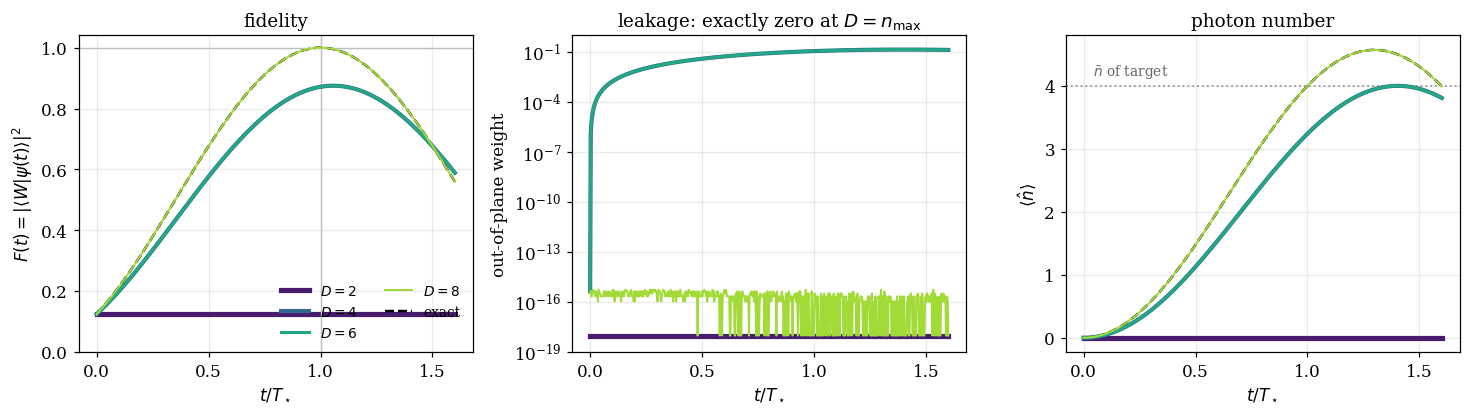

off-lattice population (n mod 4 != 0) along every trajectory:
  exact: 0.00e+00   D=2: 0.0e+00  D=4: 0.0e+00  D=6: 0.0e+00  D=8: 0.0e+00

leakage at D = n_max = 8: 5.55e-16   |F_max - 1| = 2.22e-16
trajectories that coincide exactly (same staircase plateau): [(4, 6)]


In [11]:
# Half-integer multiples of the band spacing on purpose: D = 2 and 6 sit on plateaus of
# the sec 6 staircase, D = 4 and 8 are the risers.
D_LIST = [S_SPACE + 1, 2 * (S_SPACE + 1), 3 * (S_SPACE + 1), N_MAX]
D_LIST = sorted({D for D in D_LIST if 0 < D <= N_MAX})
times = np.linspace(0, 1.6 * T_STAR, 601)

runs = {D: diagnostics(graded_H(S_MOM, NRM, REF, DIM, D, "photon"), PSI_F, times, DIM)
        for D in D_LIST}
run_ex = diagnostics(H_EXACT, PSI_F, times, DIM)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
colors = plt.cm.viridis(np.linspace(0.08, 0.86, len(D_LIST)))

# Curves on the same plateau of the sec 6 staircase coincide *exactly* (D=2 with D=3,
# D=4 with D=6, ...), so widths are staggered to keep every one of them visible.
for i, (D, c) in enumerate(zip(D_LIST, colors)):
    lw = 3.4 - 0.7 * i
    axes[0].plot(times / T_STAR, runs[D]["fid"], color=c, lw=lw, zorder=2 + i, label=f"$D={D}$")
    axes[1].semilogy(times / T_STAR, np.maximum(runs[D]["leak"], 1e-18), color=c, lw=lw,
                     zorder=2 + i)
    axes[2].plot(times / T_STAR, runs[D]["nbar"], color=c, lw=lw, zorder=2 + i)

axes[0].plot(times / T_STAR, run_ex["fid"], "k--", lw=1.6, label="exact")
axes[2].plot(times / T_STAR, run_ex["nbar"], "k--", lw=1.6)
axes[2].axhline(nbar, color="0.6", ls=":", lw=1.2)
axes[2].text(0.04, nbar * 1.04, r"$\bar n$ of target", fontsize=9, color="0.4")

axes[0].axvline(1.0, color="0.75", lw=0.9)
axes[0].axhline(1.0, color="0.75", lw=0.9)
axes[0].set(xlabel=r"$t/T_\star$", ylabel=r"$F(t)=|\langle W|\psi(t)\rangle|^2$",
            title="fidelity", ylim=(0, 1.04))
axes[0].legend(fontsize=9, ncol=2, loc="lower right")
axes[1].set(xlabel=r"$t/T_\star$", ylabel="out-of-plane weight",
            title=r"leakage: exactly zero at $D=n_{\max}$", ylim=(1e-19, 1.0))
axes[2].set(xlabel=r"$t/T_\star$", ylabel=r"$\langle \hat n\rangle$", title="photon number")
fig.tight_layout()
plt.show()

print(f"off-lattice population (n mod {2 * (S_SPACE + 1)} != 0) along every trajectory:")
print("  exact:", f"{run_ex['offlat'].max():.2e}", "  " +
      "  ".join(f"D={D}: {runs[D]['offlat'].max():.1e}" for D in D_LIST))
print(f"\nleakage at D = n_max = {N_MAX}: {runs[N_MAX]['leak'].max():.2e}"
      f"   |F_max - 1| = {abs(runs[N_MAX]['fid'].max() - 1.0):.2e}")
pairs = [(Da, Db) for Da in D_LIST for Db in D_LIST if Da < Db
         and np.abs(runs[Da]["fid"] - runs[Db]["fid"]).max() == 0.0]
print(f"trajectories that coincide exactly (same staircase plateau): {pairs}")

## 8. Why the other two schemes fail — now with an exact threshold

The binomial target separates the two failure mechanisms that were tangled together in the GKP case.
There the $n$-sum and the $k$-sum were both infinite, so a diverging $\lVert H_D\rVert$ could be
blamed on either. Here the $n$-sum is finite and complete at $D\ge n_{\max}$, so **whatever remains
wrong is the projector, and only the projector**.

Two consequences, both checked below.

* **`bare` has a finite limit and it is the wrong operator.** Beyond $D=n_{\max}$ there are no more
  bands to add, so $\lVert H_D\rVert$ stops moving in $D$ — but it still grows with $\dim_{\rm F}$, and
  the residual $\lVert H-H_{\rm exact}\rVert$ never shrinks. A pure multi-photon drive at the right
  orders with the right coefficients is simply not the time-optimal generator.
* **`degree` does eventually become exact, at an order set by the cutoff.** $\chi(q,K)$ annihilates
  $1\le q\le K$, so the band is exact once $K_n\ge\dim_{\rm F}-n-1$; with $K_n=\lfloor(D-n)/2\rfloor$
  that is
  $$D\;\ge\;2\dim_{\rm F}-n_{\min}-2 ,$$
  binding on the *smallest* surviving band $n_{\min}=2(S+1)$. So the required grading order diverges
  linearly with the numerical cutoff, and the $\dim_{\rm F}\to\infty$ limit at fixed $D$ does not
  exist — the GKP notebook's conclusion, here with the threshold in closed form.

In [12]:
# Above this much spurious phase per T*, eigh itself is no longer trustworthy and the
# "dynamics" are numerical noise rather than physics.
RESOLVE_LIMIT = 1e10

rows = []
for scheme in SCHEMES:
    for D in D_LIST:
        H = graded_H(S_MOM, NRM, REF, DIM, D, scheme)
        nrm2 = float(np.linalg.norm(H, 2))
        sv = np.linalg.svd(H, compute_uv=False)
        ratio = sv[2] / sv[0] if sv[0] > 0 else 0.0   # H is identically 0 below n_min
        err = float(np.abs(H - H_EXACT).max())
        phase = nrm2 * T_STAR
        if phase < RESOLVE_LIMIT:
            F_pk, _ = peak_fidelity_numeric(H, PSI_F, DIM, t_hi=1.6)
            d = diagnostics(H, PSI_F, np.linspace(0, 1.6 * T_STAR, 601), DIM)
            leak, dE = float(d["leak"].max()), float(d["dE"].mean())
        else:
            F_pk, leak, dE = float("nan"), float("nan"), float("nan")
        rows.append((scheme, D, nrm2, ratio, err, F_pk, leak, dE,
                     w_of_D(S_MOM, NRM, REF, D)))

print(f"{'scheme':7s} {'D':>3s} {'||H||_2':>10s} {'sig3/sig1':>10s} {'err vs exact':>12s} "
      f"{'F_peak':>9s} {'leak_max':>9s} {'dE num':>9s} {'dE an':>9s}")
for r in rows:
    tail = "  (unresolvable)" if np.isnan(r[5]) else ""
    fpk = "      ---" if np.isnan(r[5]) else f"{r[5]:9.6f}"
    lk = "      ---" if np.isnan(r[6]) else f"{r[6]:9.2e}"
    de = "      ---" if np.isnan(r[7]) else f"{r[7]:9.6f}"
    print(f"{r[0]:7s} {r[1]:3d} {r[2]:10.3e} {r[3]:10.2e} {r[4]:12.3e} "
          f"{fpk} {lk} {de} {r[8]:9.6f}{tail}")
print(f"\nAt D < n_min = {2 * (S_SPACE + 1)} every scheme gives H = 0 identically -- the selection rule")
print("of sec 3 means there is no generator at all below the first surviving band.")
print("dE(num) == dE(an) in every resolvable row, and is identical across schemes at fixed D:")
print("chi(0,K) = 1 always, so the vacuum column -- hence the speed -- is scheme-independent.")
print(f"Only `photon` reaches err = 0 at D = n_max = {N_MAX}.")

scheme    D    ||H||_2  sig3/sig1 err vs exact    F_peak  leak_max    dE num     dE an
bare      2  0.000e+00   0.00e+00    9.258e-01  0.125000  0.00e+00  0.000000  0.000000
bare      4  3.597e+02   9.43e-01    2.655e+02  0.747680  3.27e-01  0.925820  0.925820
bare      6  3.597e+02   9.43e-01    2.655e+02  0.747680  3.27e-01  0.925820  0.925820
bare      8  3.198e+03   8.89e-01    2.965e+03  0.893357  1.36e-01  1.000000  1.000000
photon    2  0.000e+00   0.00e+00    9.258e-01  0.125000  0.00e+00  0.000000  0.000000
photon    4  9.258e-01   0.00e+00    3.780e-01  0.875000  1.43e-01  0.925820  0.925820
photon    6  9.258e-01   0.00e+00    3.780e-01  0.875000  1.43e-01  0.925820  0.925820
photon    8  1.000e+00   5.14e-17    1.110e-16  1.000000  5.55e-16  1.000000  1.000000
degree    2  0.000e+00   0.00e+00    9.258e-01  0.125000  0.00e+00  0.000000  0.000000
degree    4  3.597e+02   9.43e-01    2.655e+02  0.747680  3.27e-01  0.925820  0.925820
degree    6  1.136e+04   9.15e-01    9.028e

n_min = 4;  predicted first exact D for `degree` = 2*dim_F - n_min - 2
  dim    first exact D   prediction
    16              26           26   OK
    20              34           34   OK
    24              42           42   OK
    30              54           54   OK

`bare` beyond n_max = 8:  ||H||_2 and the residual are D-independent
    D    ||H_bare||_2   err vs exact
    8    3.197731e+03    2.964643e+03
   12    3.197731e+03    2.964643e+03
   20    3.197731e+03    2.964643e+03
   39    3.197731e+03    2.964643e+03
   ... but grows with the cutoff:
  dim_F =  16:  ||H_bare||_2 =   4.9245e+01   err =   3.4205e+01
  dim_F =  24:  ||H_bare||_2 =   2.9464e+02   err =   2.6466e+02
  dim_F =  40:  ||H_bare||_2 =   3.1977e+03   err =   2.9646e+03
  dim_F =  80:  ||H_bare||_2 =   7.3753e+04   err =   6.1049e+04


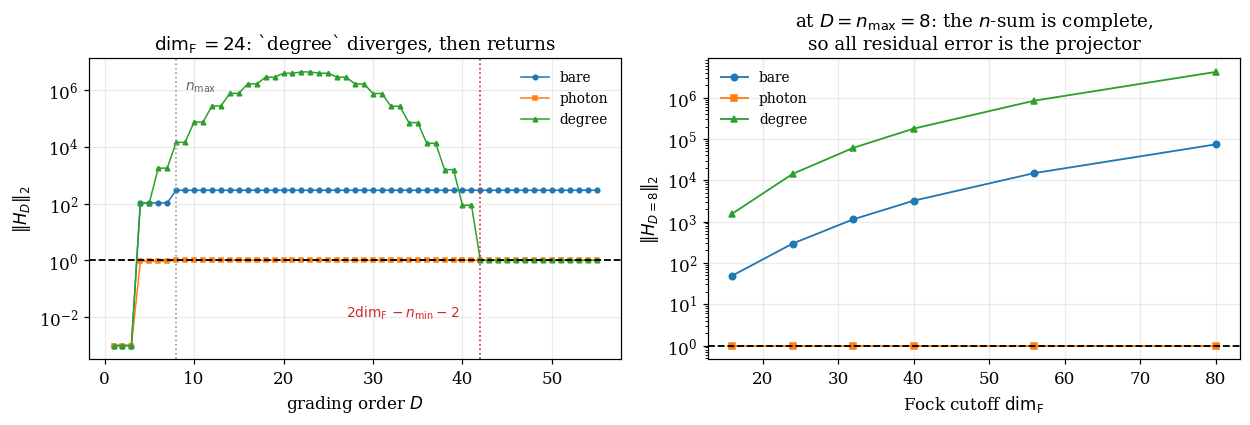

In [13]:
# The degree-scheme recovery threshold, at four cutoffs. Small dims keep the D range short.
N_MIN = 2 * (S_SPACE + 1)
print(f"n_min = {N_MIN};  predicted first exact D for `degree` = 2*dim_F - n_min - 2")
print("  dim    first exact D   prediction")
thresholds = []
for dim_t in (16, 20, 24, 30):
    S_t = binomial_moments(dim_t - 1, BRANCH, S_SPACE, N_TRUNC)
    psi_t, nrm_t = target_from_moments(dim_t, S_t)
    ref_t = reference_scalars(psi_t)
    Hx_t, _ = exact_H(psi_t, dim_t)
    first = next((D for D in range(1, 4 * dim_t)
                  if np.abs(graded_H(S_t, nrm_t, ref_t, dim_t, D, "degree") - Hx_t).max() < 1e-12),
                 None)
    pred = 2 * dim_t - N_MIN - 2
    thresholds.append((dim_t, first, pred))
    print(f"  {dim_t:4d}   {str(first):>13s}   {pred:10d}" + ("   OK" if first == pred else "   MISMATCH"))

# `bare` stops moving in D once the n-sum is exhausted, but never becomes exact,
# and still has no dim_F -> infinity limit.
print(f"\n`bare` beyond n_max = {N_MAX}:  ||H||_2 and the residual are D-independent")
print("    D    ||H_bare||_2   err vs exact")
for D in (N_MAX, N_MAX + 4, N_MAX + 12, DIM - 1):
    H = graded_H(S_MOM, NRM, REF, DIM, D, "bare")
    print(f"  {D:3d}   {np.linalg.norm(H, 2):13.6e}   {np.abs(H - H_EXACT).max():13.6e}")
print("   ... but grows with the cutoff:")
for dim_t in (16, 24, 40, 80):
    S_t = binomial_moments(dim_t - 1, BRANCH, S_SPACE, N_TRUNC)
    p_t, n_t = target_from_moments(dim_t, S_t)
    Hx_t, _ = exact_H(p_t, dim_t)
    H_t = graded_H(S_t, n_t, reference_scalars(p_t), dim_t, dim_t - 1, "bare")
    print(f"  dim_F = {dim_t:3d}:  ||H_bare||_2 = {np.linalg.norm(H_t, 2):12.4e}   "
          f"err = {np.abs(H_t - Hx_t).max():12.4e}")

# The non-monotonic excursion in between.
dim_r = 24
S_r = binomial_moments(dim_r - 1, BRANCH, S_SPACE, N_TRUNC)
psi_r, nrm_r = target_from_moments(dim_r, S_r)
ref_r = reference_scalars(psi_r)
Hx_r, _ = exact_H(psi_r, dim_r)
Dr = np.arange(1, 2 * dim_r + 8)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
for scheme, mk in zip(SCHEMES, ("o", "s", "^")):
    nn = [np.linalg.norm(graded_H(S_r, nrm_r, ref_r, dim_r, int(D), scheme), 2) for D in Dr]
    axes[0].semilogy(Dr, np.maximum(nn, 1e-3), mk + "-", ms=3.0, lw=1.0, label=scheme)
axes[0].axhline(OMEGA, color="k", ls="--", lw=1.2)
axes[0].axvline(N_MAX, color="0.6", ls=":", lw=1.1)
axes[0].axvline(2 * dim_r - N_MIN - 2, color="C3", ls=":", lw=1.1)
axes[0].text(N_MAX + 1, 1e6, r"$n_{\max}$", fontsize=9, color="0.4")
axes[0].text(2 * dim_r - N_MIN - 2 - 15, 1e-2, r"$2\dim_{\rm F}-n_{\min}-2$", fontsize=9, color="C3")
axes[0].set(xlabel="grading order $D$", ylabel=r"$\|H_D\|_2$",
            title=rf"$\dim_{{\rm F}}={dim_r}$: `degree` diverges, then returns")
axes[0].legend(fontsize=9)

# At fixed D past n_max: only `photon` has a dim -> infinity limit.
dims = np.array([16, 24, 32, 40, 56, 80])
for scheme, mk in zip(SCHEMES, ("o", "s", "^")):
    nn = []
    for dt in dims:
        S_t = binomial_moments(dt - 1, BRANCH, S_SPACE, N_TRUNC)
        p_t, n_t = target_from_moments(dt, S_t)
        nn.append(np.linalg.norm(graded_H(S_t, n_t, reference_scalars(p_t), dt, N_MAX, scheme), 2))
    axes[1].semilogy(dims, nn, mk + "-", ms=4.2, lw=1.2, label=scheme)
axes[1].axhline(OMEGA, color="k", ls="--", lw=1.2)
axes[1].set(xlabel=r"Fock cutoff $\dim_{\rm F}$", ylabel=rf"$\|H_{{D={N_MAX}}}\|_2$",
            title=rf"at $D=n_{{\max}}={N_MAX}$: the $n$-sum is complete,"
                  "\n" r"so all residual error is the projector")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## 9. Energy variance, arc length, and the speed limit

For constant $H$ both $\langle H\rangle$ and $\langle H^2\rangle$ are conserved, so the Fubini–Study
speed is constant and the arc length is $\Delta E\,t$. As in the GKP notebook,

$$\Delta E(D)=\omega\,w_D\;\le\;\omega,\qquad T_{\rm MT}(D)=\frac{\theta_B}{\Delta E(D)}\;\ge\;T_\star,$$

with $w_D$ scheme-independent and monotone. The difference is that the inequalities close: at
$D=n_{\max}$, $w_D=1$ exactly, $T_{\rm MT}=T_\star$ exactly, and the truncated generator *is* the
geodesic generator. Truncation below that can only slow the evolution — never speed it up — so no
spurious speed-limit violation can be manufactured, and the spectral-norm pathology of `bare` and
`degree` is again invisible to $\Delta E$.

In [14]:
tt = np.linspace(0, 1.6 * T_STAR, 601)
print(f"{'D':>4s} {'dE/omega':>12s} {'dE spread':>12s} {'T_MT/T*':>10s} "
      f"{'arclen(T*)/theta_B':>20s}")
for D in range(0, N_MAX + 3):
    H = graded_H(S_MOM, NRM, REF, DIM, D, "photon")
    d = diagnostics(H, PSI_F, tt, DIM)
    arclen = float(trapz(d["dE"][tt <= T_STAR], tt[tt <= T_STAR]))
    tmt = OMEGA / d["dE"].mean() if d["dE"].mean() > 0 else float("inf")
    print(f"{D:4d} {d['dE'].mean() / OMEGA:12.9f} {d['dE'].max() - d['dE'].min():12.2e} "
          f"{tmt:10.6f} {arclen / REF['theta_B']:20.9f}")

d_ex = diagnostics(H_EXACT, PSI_F, tt, DIM)
arclen_ex = float(trapz(d_ex["dE"][tt <= T_STAR], tt[tt <= T_STAR]))
print(f"\nexact: dE/omega = {d_ex['dE'].mean() / OMEGA:.12f}, "
      f"arc length at T* = {arclen_ex:.9f} vs theta_B = {REF['theta_B']:.9f}"
      f"  (MT saturation {arclen_ex / REF['theta_B']:.9f}, exact to the trapz grid)")
print(f"w_D at D = n_max: {w_of_D(S_MOM, NRM, REF, N_MAX):.14f}   (exactly 1)")

   D     dE/omega    dE spread    T_MT/T*   arclen(T*)/theta_B
   0  0.000000000     0.00e+00        inf          0.000000000
   1  0.000000000     0.00e+00        inf          0.000000000
   2  0.000000000     0.00e+00        inf          0.000000000
   3  0.000000000     0.00e+00        inf          0.000000000
   4  0.925820100     3.33e-16   1.080123          0.925820100
   5  0.925820100     3.33e-16   1.080123          0.925820100
   6  0.925820100     3.33e-16   1.080123          0.925820100
   7  0.925820100     3.33e-16   1.080123          0.925820100
   8  1.000000000     4.44e-16   1.000000          1.000000000
   9  1.000000000     4.44e-16   1.000000          1.000000000
  10  1.000000000     4.44e-16   1.000000          1.000000000

exact: dE/omega = 1.000000000000, arc length at T* = 1.209429203 vs theta_B = 1.209429203  (MT saturation 1.000000000, exact to the trapz grid)
w_D at D = n_max: 1.00000000000000   (exactly 1)


## 10. Wigner snapshots along the trajectory

For GKP the visual question was *when the grid appears*. Here it is *when the interference pattern
closes*: $|W_\uparrow\rangle$ at $(S,N)=(1,3)$ is a superposition of Fock $\{0,4,8\}$, so its Wigner
function has four-fold rotational symmetry with negative lobes, and truncating to $D=4$ drops the
$|8\rangle$ component and visibly coarsens it. At $D=n_{\max}$ the final frame is the target exactly,
not approximately — the row is a pixel-level reproduction of the `exact` row.

The Wigner routine is the one from the GKP notebook: position space,
$W(x,p)=\frac1\pi\int dy\,\psi^*(x{+}y)\psi(x{-}y)e^{2ipy}$, with normalized Hermite functions from
the stable recursion $h_n=\sqrt{2/n}\,x\,h_{n-1}-\sqrt{(n{-}1)/n}\,h_{n-2}$. Conventions match the
project, $x=(\hat a+\hat a^\dagger)/\sqrt2$ and $\int W\,dx\,dp=1$, so `utils.compute_wigner` can be
swapped in directly.

In [15]:
def hermite_funcs(nmax, x):
    """h_n(x) = pi^{-1/4}(2^n n!)^{-1/2} H_n(x) e^{-x^2/2}, by stable recursion."""
    x = np.asarray(x, float)
    H = np.empty((nmax + 1,) + x.shape)
    H[0] = pi ** -0.25 * np.exp(-x ** 2 / 2)
    if nmax >= 1:
        H[1] = sqrt(2.0) * x * H[0]
    for n in range(2, nmax + 1):
        H[n] = sqrt(2.0 / n) * x * H[n - 1] - sqrt((n - 1) / n) * H[n - 2]
    return H


def wigner_numpy(psi, xg, pg, ny=401, pad=2.5):
    """W(x,p) with x=(a+adag)/sqrt2; integral over dx dp is 1."""
    nmax = len(psi) - 1
    ymax = max(abs(xg[0]), abs(xg[-1])) + pad
    yg = np.linspace(-ymax, ymax, ny)
    Hp = hermite_funcs(nmax, xg[:, None] + yg[None, :])
    Hm = hermite_funcs(nmax, xg[:, None] - yg[None, :])
    M = np.conj(np.tensordot(psi, Hp, axes=(0, 0))) * np.tensordot(psi, Hm, axes=(0, 0))
    return np.real(M @ np.exp(2j * np.outer(pg, yg)).T).T / pi * (yg[1] - yg[0])


# validation
xg = pg = np.linspace(-7.0, 7.0, 181)
Xg, Pg = np.meshgrid(xg, pg)
r2 = Xg ** 2 + Pg ** 2
dA = (xg[1] - xg[0]) * (pg[1] - pg[0])
for n in (0, 2, 6):
    v = np.zeros(40, complex); v[n] = 1.0
    W = wigner_numpy(v, xg, pg)
    Wex = (1 / pi) * (-1) ** n * eval_laguerre(n, 2 * r2) * np.exp(-r2)
    print(f"Fock |{n}>: max|W - W_exact| = {np.abs(W - Wex).max():.2e},  "
          f"int W dx dp = {W.sum() * dA:.10f}")
print(f"target state: int W dx dp = {wigner_numpy(PSI_F, xg, pg).sum() * dA:.8f}"
      "   <- deviation from 1 is grid clipping, so widen the window if it grows")

Fock |0>: max|W - W_exact| = 4.05e-15,  int W dx dp = 1.0000000000
Fock |2>: max|W - W_exact| = 3.83e-15,  int W dx dp = 1.0000000000
Fock |6>: max|W - W_exact| = 3.55e-15,  int W dx dp = 1.0000000000
target state: int W dx dp = 1.00000000   <- deviation from 1 is grid clipping, so widen the window if it grows


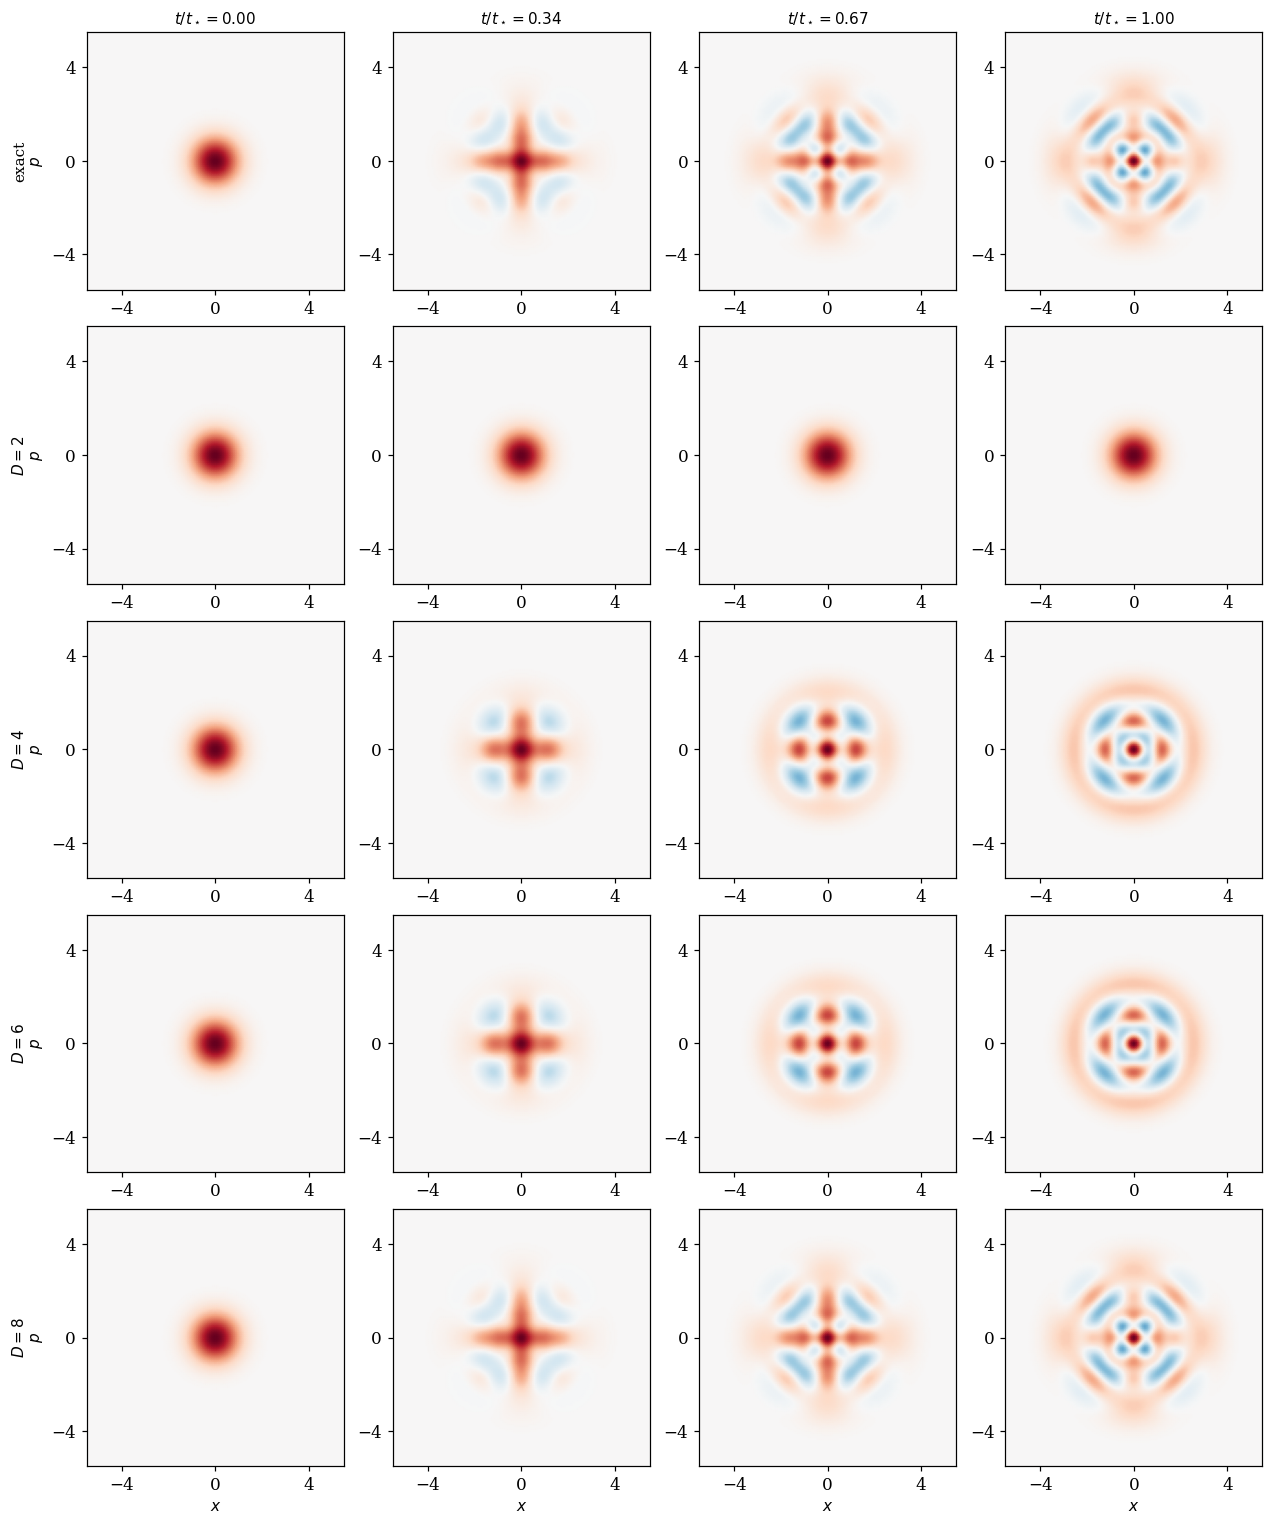

final frame vs target Wigner: max|W - W_target| = 2.22e-16


In [16]:
frac = np.array([0.0, 0.34, 0.67, 1.0])
panels = [("exact", H_EXACT)] + [(f"$D={D}$", graded_H(S_MOM, NRM, REF, DIM, D, "photon"))
                                 for D in D_LIST]
xw = pw = np.linspace(-5.5, 5.5, 141)

fig, axes = plt.subplots(len(panels), len(frac), figsize=(11.5, 2.75 * len(panels)),
                         constrained_layout=True)
W_tgt = wigner_numpy(PSI_F, xw, pw)
vmax = float(np.abs(W_tgt).max())
norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

for row, (label, H) in enumerate(panels):
    tp = peak_fidelity_numeric(H, PSI_F, DIM)[1]
    psis = trajectory(H, frac * tp, DIM)
    for col, f in enumerate(frac):
        ax = axes[row, col]
        ax.pcolormesh(xw, pw, wigner_numpy(psis[col], xw, pw), cmap="RdBu_r",
                      norm=norm, shading="gouraud", rasterized=True)
        ax.set_aspect("equal"); ax.set_xticks([-4, 0, 4]); ax.set_yticks([-4, 0, 4])
        ax.grid(False)
        if row == 0:
            ax.set_title(rf"$t/t_\star={f:.2f}$", fontsize=10)
        if col == 0:
            ax.set_ylabel(label + "\n$p$", fontsize=10)
for col in range(len(frac)):
    axes[-1, col].set_xlabel("$x$", fontsize=10)
try:
    fig.savefig("../../figs/brachistochrone/wigner_trajectories_binomial.pdf",
                format="pdf", bbox_inches="tight")
except (FileNotFoundError, OSError) as exc:
    print(f"(figure not written: {exc})")
plt.show()

W_end = wigner_numpy(trajectory(H_EXACT, np.array([T_STAR]), DIM)[0], xw, pw)
print(f"final frame vs target Wigner: max|W - W_target| = {np.abs(W_end - W_tgt).max():.2e}")

## 11. $D_\star$ is the stellar rank, and that is why GKP does not terminate

Collecting §3 and §6: the required non-linear order is

$$D_\star=n_{\max}=2(S+1)\Bigl\lfloor\frac{N+1}2\Bigr\rfloor
\;\overset{N\ \mathrm{odd}}{=}\;(S+1)(N+1)=2\bar n ,$$

reached with only $\lfloor(N+1)/2\rfloor$ distinct wave-mixing processes. There is nothing to sweep
and no threshold to choose — $F_\star(D_\star)=1$ exactly, so the $D_\star(F_\star)$ table that the
GKP notebook needed collapses to a single column.

The reason is structural, and it is the same quantity that appears in the manuscript's three-tier
argument. A state with finite Fock support has a *polynomial* stellar function, of degree $n_{\max}$,
hence **stellar rank $n_{\max}$**; the time-optimal generator is that polynomial in $\hat a^\dagger$
times the vacuum projector, and the $n$-sum inherits the degree. GKP states have stellar functions
built from Jacobi theta functions, whose zeros have positive density in $\mathbb C$, hence **infinite
stellar rank** — and the same formula then returns no finite $D_\star$. One statement, both answers:

$$D_\star=\mathrm{rank}_\star(|\psi_f\rangle).$$

The final cell makes the comparison at matched $\bar n$, which is the fair axis: the binomial code at
$\bar n=4$ terminates at $D=8$ with zero residual, while GKP at the $\Delta$ that gives the same
$\bar n$ still carries $\sim6\%$ infidelity at $D=8$ and needs $D=22$ just to reach $0.99$.

In [17]:
print(f"{'S':>2s} {'N':>2s} {'n_max':>6s} {'2(S+1)|_(N+1)/2|':>17s} {'bands':>6s} "
      f"{'nbar':>6s} {'|s|^2':>8s} {'theta_B':>8s} {'F*(n_max)':>11s} {'F* num':>11s}")
fam = [(1, 1), (1, 2), (1, 3), (1, 5), (1, 7), (2, 3), (2, 5), (3, 4)]
for (S_t, N_t) in fam:
    nmax_t = 2 * (S_t + 1) * ((N_t + 1) // 2)
    dim_t = nmax_t + 12
    S_v = binomial_moments(dim_t - 1, "up", S_t, N_t)
    psi_t, nrm_t = target_from_moments(dim_t, S_v)
    ref_t = reference_scalars(psi_t)
    sup_max = int(np.flatnonzero(np.abs(psi_t) > 1e-14)[-1])
    H_t = graded_H(S_v, nrm_t, ref_t, dim_t, nmax_t, "photon")
    F_num, _ = peak_fidelity_numeric(H_t, psi_t, dim_t, t_scale=ref_t["T_star"], t_hi=1.6)
    print(f"{S_t:2d} {N_t:2d} {sup_max:6d} {nmax_t:17d} {(N_t + 1) // 2:6d} "
          f"{np.sum(np.arange(dim_t) * np.abs(psi_t) ** 2):6.2f} {abs(ref_t['s']) ** 2:8.4f} "
          f"{ref_t['theta_B']:8.4f} {binomial_partial_sum(nmax_t, 'up', S_t, N_t):11.8f} "
          f"{F_num:11.8f}")
print("\nn_max column == formula column in every row, and F*(n_max) = 1 exactly.")

 S  N  n_max  2(S+1)|_(N+1)/2|  bands   nbar    |s|^2  theta_B   F*(n_max)      F* num
 1  1      4                 4      1   2.00   0.5000   0.7854  1.00000000  1.00000000
 1  2      4                 4      1   3.00   0.2500   1.0472  1.00000000  1.00000000
 1  3      8                 8      2   4.00   0.1250   1.2094  1.00000000  1.00000000
 1  5     12                12      3   6.00   0.0312   1.3931  1.00000000  1.00000000
 1  7     16                16      4   8.00   0.0078   1.4823  1.00000000  1.00000000
 2  3     12                12      2   6.00   0.1250   1.2094  1.00000000  1.00000000
 2  5     18                18      3   9.00   0.0312   1.3931  1.00000000  1.00000000
 3  4     16                16      2  10.00   0.0625   1.3181  1.00000000  1.00000000

n_max column == formula column in every row, and F*(n_max) = 1 exactly.


binomial (S,N)=(1,3):  nbar = 4.000   D* = 8 (exact, 1-F* = 0)
GKP Delta = 0.33 (9.6 dB): nbar = 4.061   D*(0.99) = 22   D*(0.999) = 28
  GKP residual infidelity at D = 8: 0.0589


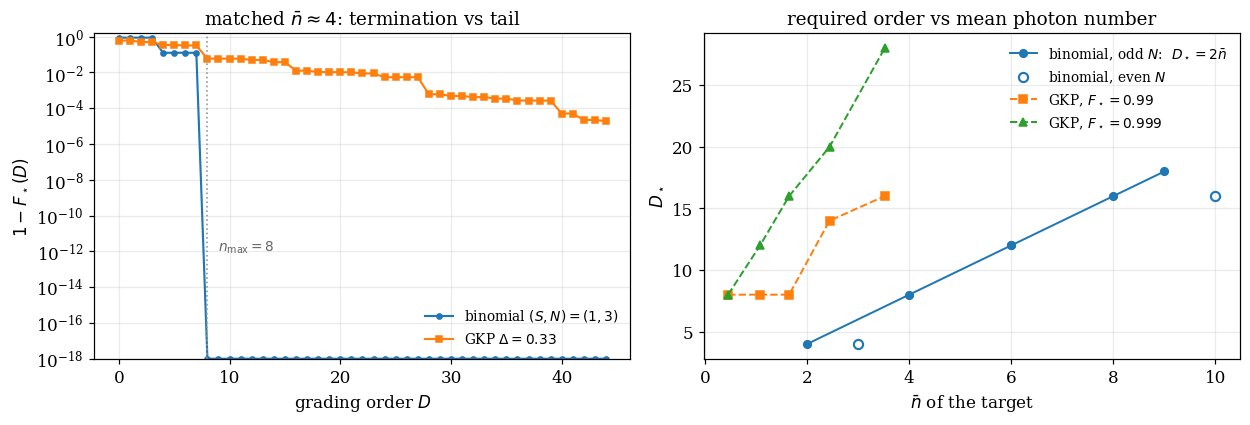

In [18]:
# Matched-nbar comparison against GKP. Lattice machinery lifted from notebook 2 sec 2.
def lattice_moments(nmax, mu, alpha_v, beta_v, delta_v, cutoff):
    """S_n^{(mu)} for a square-lattice GKP state (notebook 2 convention)."""
    S = np.zeros(nmax + 1, complex)
    powers = np.arange(nmax + 1)
    for jj in range(-cutoff, cutoff + 1):
        for ll in range(-cutoff, cutoff + 1):
            m = 2 * jj + mu
            z = m * alpha_v + ll * beta_v
            weight = np.exp(-1j * pi * m * ll / 2) * np.exp(-abs(z) ** 2 / 2)
            zd = np.exp(-delta_v ** 2) * z
            if zd == 0:
                pw = np.zeros(nmax + 1, complex); pw[0] = 1.0
            else:
                pw = np.exp(powers * np.log(abs(zd)) + 1j * powers * np.angle(zd))
            S += weight * pw
    return S


ALPHA_G, BETA_G, DELTA_G, CUT_G, DIM_G = sqrt(pi / 2), 1j * sqrt(pi / 2), 0.33, 5, 110
S_G = lattice_moments(DIM_G - 1, 0, ALPHA_G, BETA_G, DELTA_G, CUT_G)
PSI_G, _ = target_from_moments(DIM_G, S_G)
nbar_G = float(np.sum(np.arange(DIM_G) * np.abs(PSI_G) ** 2))
cum_G = np.cumsum(np.abs(PSI_G) ** 2)

print(f"binomial (S,N)=({S_SPACE},{N_TRUNC}):  nbar = {nbar:.3f}   D* = {N_MAX} (exact, 1-F* = 0)")
print(f"GKP Delta = {DELTA_G} ({-10 * np.log10(DELTA_G ** 2):.1f} dB): nbar = {nbar_G:.3f}   "
      f"D*(0.99) = {int(np.searchsorted(cum_G, 0.99))}   D*(0.999) = {int(np.searchsorted(cum_G, 0.999))}")
print(f"  GKP residual infidelity at D = {N_MAX}: {float(np.sum(np.abs(PSI_G[N_MAX + 1:]) ** 2)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
Dg = np.arange(0, 45)
tail_b = np.array([max(1 - binomial_partial_sum(int(D), BRANCH, S_SPACE, N_TRUNC), 0.0) for D in Dg])
tail_g = np.array([float(np.sum(np.abs(PSI_G[D + 1:]) ** 2)) for D in Dg])
axes[0].semilogy(Dg, np.maximum(tail_b, 1e-18), "o-", ms=3.4, lw=1.4,
                 label=rf"binomial $(S,N)=({S_SPACE},{N_TRUNC})$")
axes[0].semilogy(Dg, np.maximum(tail_g, 1e-18), "s-", ms=3.4, lw=1.4,
                 label=rf"GKP $\Delta={DELTA_G}$")
axes[0].axvline(N_MAX, color="0.6", ls=":", lw=1.1)
axes[0].text(N_MAX + 1, 1e-12, rf"$n_{{\max}}={N_MAX}$", fontsize=9, color="0.4")
axes[0].set(xlabel="grading order $D$", ylabel=r"$1-F_\star(D)$",
            title=rf"matched $\bar n\approx{nbar:.0f}$: termination vs tail", ylim=(1e-18, 1.5))
axes[0].legend(fontsize=9)

# D* vs nbar across the binomial family, against GKP at several Delta.
# D* = 2 nbar holds only for odd N; even N loses the top p-term to the p <= N+1 cutoff,
# so those points sit below the line. Plotted separately to keep that visible.
nb_odd, ds_odd, nb_even, ds_even = [], [], [], []
for (S_t, N_t) in fam:
    nb_t = (S_t + 1) * (N_t + 1) / 2
    ds_t = 2 * (S_t + 1) * ((N_t + 1) // 2)
    (nb_odd if N_t % 2 else nb_even).append(nb_t)
    (ds_odd if N_t % 2 else ds_even).append(ds_t)
o = np.argsort(nb_odd)
axes[1].plot(np.array(nb_odd)[o], np.array(ds_odd)[o], "o-", ms=5, lw=1.3,
             label=r"binomial, odd $N$:  $D_\star=2\bar n$")
axes[1].plot(nb_even, ds_even, "o", ms=6, mfc="none", mew=1.4, color="C0",
             label=r"binomial, even $N$")
nb_g, ds_g99, ds_g999 = [], [], []
for dl, cut, dim_s in [(0.60, 3, 40), (0.50, 3, 50), (0.45, 4, 60), (0.40, 4, 80), (0.35, 5, 100)]:
    S_s = lattice_moments(dim_s - 1, 0, ALPHA_G, BETA_G, dl, cut)
    psi_s, _ = target_from_moments(dim_s, S_s)
    cum = np.cumsum(np.abs(psi_s) ** 2)
    nb_g.append(float(np.sum(np.arange(dim_s) * np.abs(psi_s) ** 2)))
    ds_g99.append(int(np.searchsorted(cum, 0.99)))
    ds_g999.append(int(np.searchsorted(cum, 0.999)))
axes[1].plot(nb_g, ds_g99, "s--", ms=5, lw=1.3, label=r"GKP, $F_\star=0.99$")
axes[1].plot(nb_g, ds_g999, "^--", ms=5, lw=1.3, label=r"GKP, $F_\star=0.999$")
axes[1].set(xlabel=r"$\bar n$ of the target", ylabel=r"$D_\star$",
            title=r"required order vs mean photon number")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## 12. The other branch: $|W_\downarrow\rangle$ and an orthogonal target

$|W_\downarrow\rangle$ is supported on odd $p$, so it has **no vacuum component**:
$s=\langle0|W_\downarrow\rangle=0$. That is the degenerate corner of the brachistochrone
construction, and worth exercising because it is the corner a state-*transfer* problem lands in.

With $s=0$ we get $R=1$, $\theta_B=\pi/2$, $T_\star=\pi/(2\omega)$, and $\phi$ is undefined — the
generator is fixed only up to the free phase that $\arg s$ would have set, which is a gauge freedom
here rather than a problem, since $|0\rangle\perp|W_\downarrow\rangle$ means any choice rotates
vacuum onto the target in the same time. The selection rule shifts to
$n\equiv(S+1)\pmod{2(S+1)}$, the expansion still terminates, and the $F_\star$ staircase becomes the
odd-$p$ partial sum, starting from $F_\star=0$ rather than $|s|^2$.

In [19]:
S_DN = binomial_moments(DIM - 1, "down", S_SPACE, N_TRUNC)
PSI_DN, NRM_DN = target_from_moments(DIM, S_DN)
REF_DN = reference_scalars(PSI_DN)
H_DN, _ = exact_H(PSI_DN, DIM)
NMAX_DN = int(np.flatnonzero(np.abs(PSI_DN) > 1e-14)[-1])

print(f"|W_down>: support {[int(n) for n in np.flatnonzero(np.abs(PSI_DN) > 1e-14)]}"
      f"   n_max = {NMAX_DN}")
print(f"  s = {REF_DN['s']:.1e}   R = {REF_DN['R']:.12f}   theta_B = {REF_DN['theta_B']:.12f} "
      f"(pi/2 = {pi / 2:.12f})")
print(f"  T* = {REF_DN['T_star']:.12f}   nbar = {float(np.sum(np.arange(DIM) * np.abs(PSI_DN) ** 2)):.10f}")
print(f"  ||H_exact||_2 = {np.linalg.norm(H_DN, 2):.14f}\n")

print("   D   ||H_photon - H_exact||_max   F* analytic     F* binomial    F* numeric")
for D in range(0, NMAX_DN + 4):
    H = graded_H(S_DN, NRM_DN, REF_DN, DIM, D, "photon")
    Fa, _, _ = peak_fidelity_analytic(S_DN, NRM_DN, REF_DN, D)
    Fb = binomial_partial_sum(D, "down", S_SPACE, N_TRUNC)
    Fn = 0.0 if D == 0 else peak_fidelity_numeric(H, PSI_DN, DIM,
                                                  t_scale=REF_DN["T_star"], t_hi=1.4)[0]
    flag = "   <- exact" if np.abs(H - H_DN).max() < 1e-15 else ""
    print(f"  {D:2d}   {np.abs(H - H_DN).max():26.2e}   {Fa:.10f}    {Fb:.10f}   "
          f"{Fn:.10f}{flag}")

# The gauge freedom: any phi gives the same T* when s = 0.
print("\nphi is a gauge freedom at s = 0 (peak fidelity and time vs an imposed phase):")
for phi_try in (0.0, 0.7, pi / 2, 2.3):
    ref_try = dict(REF_DN, phi=phi_try)
    H_try = graded_H(S_DN, NRM_DN, ref_try, DIM, NMAX_DN, "photon")
    F_try, t_try = peak_fidelity_numeric(H_try, PSI_DN, DIM,
                                         t_scale=REF_DN["T_star"], t_hi=1.4)
    print(f"  phi = {phi_try:5.3f}:  F_peak = {F_try:.10f}   t*/T_star = {t_try / REF_DN['T_star']:.8f}")

|W_down>: support [2, 6]   n_max = 6
  s = 0.0e+00   R = 1.000000000000   theta_B = 1.570796326795 (pi/2 = 1.570796326795)
  T* = 1.570796326795   nbar = 4.0000000000
  ||H_exact||_2 = 1.00000000000000

   D   ||H_photon - H_exact||_max   F* analytic     F* binomial    F* numeric
   0                     7.07e-01   0.0000000000    0.0000000000   0.0000000000
   1                     7.07e-01   0.0000000000    0.0000000000   0.0000000000
   2                     7.07e-01   0.5000000000    0.5000000000   0.4998753910
   3                     7.07e-01   0.5000000000    0.5000000000   0.4998753910
   4                     7.07e-01   0.5000000000    0.5000000000   0.4998753910
   5                     7.07e-01   0.5000000000    0.5000000000   0.4998753910
   6                     1.11e-16   1.0000000000    1.0000000000   1.0000000000   <- exact
   7                     1.11e-16   1.0000000000    1.0000000000   1.0000000000   <- exact
   8                     1.11e-16   1.0000000000    1.000

## 13. Reading, and where it plugs in

**The control passes, and it passes exactly.** Every asymptotic statement in
`gkp_brachistochrone_graded_trajectory.ipynb` has a finite counterpart here: the `photon` expansion
terminates at $D=n_{\max}$ with identically zero residual at any Fock cutoff (§5), the peak fidelity
is a binomial partial sum rather than a decaying tail (§6), $w_D$ reaches exactly $1$ so
Mandelstam–Tamm is saturated by a finite-order generator (§9), and the trajectory's leakage from the
geodesic plane is exactly zero rather than small (§7). The machinery is therefore doing what it
claims; the heavy tails in the GKP case are a property of GKP states, not an artifact of the
expansion.

**$D_\star$ is the stellar rank, and that is the sharp statement to carry back to the manuscript.**
$D_\star=\mathrm{rank}_\star(|\psi_f\rangle)$ covers both cases: finite for any finite Fock
superposition, infinite for a theta-function stellar amplitude. This is the same conclusion as the
three-tier necessity argument, arrived at without any lattice-specific input, which makes it a
useful independent check on tier 2 — and it says the GKP obstruction is not about lattices, envelope
widths, or wave mixing *per se*, but about stellar rank alone.

**The projector is still irreducible, and this notebook isolates that.** With the $n$-sum finite and
complete, anything still wrong at $D\ge n_{\max}$ is the vacuum projector and nothing else — so the
`bare` scheme's finite-but-wrong limit and the `degree` scheme's $D=2\dim_{\rm F}-n_{\min}-2$
threshold (§8) are clean measurements of projector-truncation error with no tail confound. The
threshold's linear growth in $\dim_{\rm F}$ is the crispest available statement that the $d$-grading
is not a physical expansion parameter.

**What this buys operationally.** A binomial target is the right first test case for anything in the
pipeline that was hard to validate on GKP: the exact generator is two terms at $(S,N)=(1,3)$, the
geodesic is closed-form, $T_\star=\arccos2^{-N/2}$ is exact, and $F_\star=1$ is reachable, so a
fidelity below $1$ in a gate-sequence fit is unambiguously the fit's fault. The off-lattice
population check of §7 is also strictly stronger than the GKP parity check, and free.

**Suggested follow-ups.**

1. Run the ECD and SNAP+displacement fits against the §6 geodesic for $(S,N)=(1,3)$ before running
   them on GKP. With $F_\star=1$ exactly attainable and only two wave-mixing orders in $H_{\rm opt}$,
   this is the depth-annealing test case where landscape flatness can be distinguished from a genuine
   algebraic ceiling.
2. The Fubini–Study arc-length diagnostic on the roadmap should be calibrated here first: $\Delta E$
   saturates $\omega$ exactly at $D=n_{\max}$, so the MT reference $T_{\rm MT}=\theta_B/\Delta E$ has a
   known exact value to compare optimized circuits against.
3. Cat codes are the natural third control — finite stellar rank is lost (coherent states are
   rank $0$, but their superpositions are not finite Fock sums), so $D_\star$ should be infinite as
   for GKP while the state stays far simpler. That would test whether stellar rank or Fock support is
   the operative quantity in §11.
4. Interpolate: the $\mathbb Z_{2(S+1)}$ rule means $|W_\uparrow\rangle$ with large $S$ and small $N$
   is a two-component superposition with very high $n_{\max}$. Sweeping $S$ at fixed $N$ separates
   "many required orders" from "many required processes", which the GKP case conflates.